In [ ]:
# Initialize Otter
import otter
grader = otter.Notebook("cs1090a_hw3.ipynb")

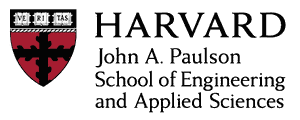

# CS1090A Introduction to Data Science
## Homework 3: How much should you trust the model?
### Regularization, bootstrap inference, missing data, and principal components

**Harvard University**<br/>
**Fall 2026**<br/>
**Instructors**: Pavlos Protopapas, Kevin Rader, and Chris Gumb

<hr style="height:2.4pt">

## Instructions

CS1090A is graded out of 100 points. AC209A students complete the two marked extensions and are graded out of 110.

Run the import cell before beginning, then run each supplied data or settings cell when you reach it. These cells appear beside the questions that use them. Your submitted notebook must run in order after restarting the kernel, using the supplied local files. Include visible outputs, labeled plots, and written answers, and follow the Canvas submission instructions.

Use the supplied partitions and keep test data reserved until the final evaluation questions.

**Use of AI tools**

You may use AI tools. You are accountable for everything you submit: you must understand it and be able to explain it.

- Written answers must be your own words.
- Quizzes and midterms ask you to explain and apply these methods without a tool.

All plots must have axis labels, a descriptive title, and a legend when colors, symbols, or reference lines distinguish information. Include units where applicable.

Written-response requests under **Constraints** are required parts of your answer, as are those listed under **Task** and **Artifacts**.


In [ ]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso, lasso_path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import norm
from threadpoolctl import threadpool_limits
from hw3_support import (
    CORE,
    FrontageImputer,
    AmesPreprocessor,
    reference_pipeline,
    load_ames,
    fixed_folds,
    bootstrap_folds,
    support_checkpoint,
    checked_ols,
    bootstrap_coefficient_maps,
    load_cookie,
    load_cookie_test,
)

from hw3_cache import cached_bootstrap_results

thread_limit = threadpool_limits(limits=1)
notebook_start = time.time()


# Part 1. Missingness and imputation

We return to the Ames housing data from Homework 2 to predict the natural logarithm of sale price. Before fitting regression models, investigate the missing measurements and decide how to replace them. The supplied loading and preparation code lets you begin with that investigation without repeating the earlier data-cleaning exercises.

We will use three fixed, disjoint groups of houses throughout the Ames questions. The supplied cell below loads the data and creates the variables listed here; run it before Q1.1.

| Group | Variables | Houses | Purpose |
|---|---|---:|---|
| Selection | `X_selection`, `y_selection` | 1,318 | Investigate missingness, tune models using cross-validation, and select predictors. Use these houses for Part 1. |
| Inference | `X_inference`, `y_inference` | 879 | Estimate the selected coefficients and assess uncertainty and predictive importance in Part 3. Keep these outcomes out of predictor selection. |
| Test | `partitions['test']` | 733 | Evaluate the frozen final procedures in Q3.8. Do not inspect or use these houses in the earlier analyses. |

Each `X_...` table contains recorded predictors; its matching `y_...` array contains the natural logarithm of sale price, in the same row order. The selection and inference groups together form the non-test training data. Reserving fresh inference outcomes lets us assess coefficients without reusing the price evidence that selected their predictors; Part 3 explains that distinction in more detail.

`raw_ames` preserves the source records, including recorded zeros. `ames_x` contains the predictor columns prepared by the loader, with unknown frontage marked as missing. `selection_ids` contains the row labels of the houses in the selection partition; `inference_ids` does the same for the inference partition. These labels let us retrieve the corresponding original records from `raw_ames`. In Q1.1, use `raw_ames.loc[selection_ids]` for recorded-zero counts and `X_selection` for missing-value counts. Later Part 1 questions also use the selection houses. The fixed splits and helper definitions ensure everyone can work from the same starting data.


<details>
<summary><b>Column descriptions</b> (click to expand)</summary>

| Column | What it records |
|---|---|
| `Gr_Liv_Area` | above-ground living area, square feet |
| `Total_Bsmt_SF` | basement area, square feet (0 if no basement) |
| `First_Flr_SF` | first-floor area, square feet |
| `Garage_Cars` | garage capacity, in cars (0 if no garage) |
| `Garage_Area` | garage area, square feet (0 if no garage) |
| `Year_Built` | year the house was built |
| `Year_Remod_Add` | year of the last remodel (equals `Year_Built` if never remodelled) |
| `Full_Bath` | full bathrooms above ground |
| `TotRms_AbvGrd` | rooms above ground, not counting bathrooms |
| `Lot_Area` | lot size, square feet |
| `Lot_Frontage` | feet of street connected to the lot; recorded zeros in this file indicate unknown frontage |
| `Mas_Vnr_Area` | masonry veneer area, square feet |
| `Year_Sold` | year of the sale, 2006 to 2010 |
| `Neighborhood` | the named area of Ames where the house is located |
| `Overall_Qual` | rating of the house's material and finish, 10 levels from `Very_Poor` to `Very_Excellent` |
| `House_Style` | e.g. one storey, two storeys, split level |
| `Sale_Condition` | e.g. `Normal`, `Partial` (a new house sold before completion), `Abnorml` (a foreclosure or short sale) |
| `Kitchen_Qual` | kitchen quality, 5 levels |
| `Bldg_Type` | single-family, townhouse, duplex, and so on |
| `Misc_Feature` | a shed, tennis court or similar; `None` means the amenity is absent |
| `Exter_Qual` | exterior material quality, 4 levels |
| `Mas_Vnr_Type` | type of masonry veneer; `None` means the amenity is absent |
| `Central_Air` | `Y` or `N` |
| `Sale_Price` | **the target**, in dollars |

For descriptions of the remaining fields and category codes, see the [complete Ames data dictionary](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) and the [column names in the supplied version](https://modeldata.tidymodels.org/reference/ames.html).

</details>


In [ ]:
# Supplied Ames loading and fixed partitions; see the table above.
raw_ames, ames_x, partitions, prep_template = load_ames()
selection_ids = partitions["selection"]
inference_ids = partitions["inference"]
X_selection = ames_x.loc[selection_ids].copy()
y_selection = np.log(raw_ames.loc[selection_ids, "Sale_Price"].to_numpy())
X_inference = ames_x.loc[inference_ids].copy()
y_inference = np.log(raw_ames.loc[inference_ids, "Sale_Price"].to_numpy())
# Cross-validation indices are positions within the selection tables, not row labels.
selection_folds = fixed_folds(len(X_selection))
print({name: len(ids) for name, ids in partitions.items()})


## Q1.1. Audit recorded measurements

**3 points**

Before we begin modeling prices, we need to understand what information is available about each house. A recorded zero can describe an absent amenity, such as a pool, or stand in for an unknown measurement. These meanings call for different treatment: replacing a genuine zero would change the recorded characteristics of the house.

**Task:** Use `raw_ames.loc[selection_ids]` to count recorded zeros, and `X_selection` to count missing predictor values. Report predictors with at least one blank or zero. Confirm the meanings of zeros in `Lot_Frontage`, `Garage_Area`, and `Pool_Area` using related columns and the [Ames data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt). Calculate how many selection houses remain if every row with a missing predictor is deleted.

**Artifacts:** A table showing missing-value and zero counts by predictor; the number and proportion of selection houses retained by complete-case deletion; and a short explanation of which values represent unknown measurements versus absent amenities.

**Constraints:** Preserve raw missingness; distinguish unknown frontage from genuine zeros. Do not repeat Homework 2 encoding or feature engineering.

**Output names for the guided checks:** `audit` (a missingness table) and `complete_rows` (the retained-row count).

The supplied loader preserves literal `None` amenity categories and marks zero frontage as unknown in `X_selection`. In the supplied selection rows, frontage is the only predictor with missing values; this does not make zeros in other predictors missing.

The supplied CSV has basement-type codes in `BsmtFin_SF_1`, rather than area measurements. The loader excludes this mislabeled duplicate; other basement measurements remain.


In [ ]:
# Your code here
...


In [ ]:
grader.check("q1_1")

**Written response — Q1.1**

*Write your explanation and interpretation here.*


## Q1.2. Investigate the consequences of deletion

**3 points**

The audit shows which houses we would lose if we simply dropped rows with missing measurements. Deletion reduces the sample size, but it can also change which kinds of houses are represented. If missingness is more common in particular neighborhoods or types of properties, the remaining data may give a distorted picture of the population we want to model.

**Task:** Relate missing-frontage indicators to neighborhood and other recorded lot characteristics, displaying group sizes. Interpret evidence relevant to complete-case deletion.

**Artifacts:** A neighborhood summary showing group sizes and missing-frontage rates; one comparison with a recorded lot characteristic; and a short explanation of whether deleting incomplete houses would change the represented population.

**Constraints:** Use selection data. Patterns can challenge MCAR but do not conclusively distinguish MAR from MNAR.

In [ ]:
# Your code here
...


**Written response — Q1.2**

*Write your explanation and interpretation here.*


## Q1.3. Establish a simple imputation baseline

**2 points**

Imputation offers a way to retain houses whose measurements are incomplete. A simple rule, such as replacing unknown frontage with the observed median, gives us a useful reference before we try more elaborate methods. Its simplicity also makes its limitations visible: every house with unknown frontage receives the same replacement, regardless of its other characteristics.

**Task:** Use `FrontageImputer('median')` to fit an overall median replacement rule on the selection data. Apply it to unknown frontage values and compare the replacement distribution with the observed frontage distribution.

**Artifacts:** The filled selection predictors, a distribution comparison, and a short explanation of what the median rule preserves and what it does not capture.

**Constraints:** Fit using observed fitting-sample values; replace only unknown frontage; no sale-price inputs.

**Output names for the guided checks:** `median_filled` (the selection predictors after applying the baseline).


In [ ]:
# Your code here
...


In [ ]:
grader.check("q1_3")

**Written response — Q1.3**

*Write your explanation and interpretation here.*


## Q1.4. Use recorded characteristics for imputation

**4 points**

The median baseline ignores information we already have about each house. Street frontage may differ across neighborhoods and may be related to lot size, so these recorded characteristics could help us choose more plausible replacements. Comparing these approaches lets us investigate what additional information contributes before deciding whether the extra complexity is worthwhile.

**Task:** Fit and apply `FrontageImputer('neighborhood')` and `FrontageImputer('regression')`. The neighborhood rule uses an overall median when a fitting sample has no observed frontage for a neighborhood. The regression rule uses square-root lot area. Compare their replacement values with the median baseline, and assess whether their ranges and variation are plausible.

Note any neighborhoods with few or no observed frontages available to fit their replacement rule.

**Artifacts:** Replacement-value summaries for all three methods, a distribution plot, and a short comparison. Keep the method names for Q1.5, where each rule must be refitted within the relevant fold; do not reuse the rules fitted here on all selection rows.

**Constraints:** Fit only on observed frontage; exclude sale price; retain measurements actually observed.

In [ ]:
# Your code here
...


**Written response — Q1.4**

*Write your explanation and interpretation here.*


## Q1.5. Validate replacements and use the shared pipeline

**6 points**

The replacement distributions show whether an imputation method produces plausible values, but plausibility alone does not establish accuracy. Hiding measurements we actually know lets us compare replacements with their recorded values. When we then evaluate price predictions, we also need to consider when the imputer was fitted: held-out houses should not help determine the preprocessing used to predict them.

**Task:**
1. Restrict the reconstruction exercise to selection houses with observed frontage. Define `observed_positions` as their positional indices within `X_selection`. Use `fixed_folds(len(observed_positions), seed=109)` Each fold’s index arrays point into `observed_positions`; for example, its held-out houses are `X_selection.iloc[observed_positions[va]]`. In each fold, hide the held-out frontage, fit each `FrontageImputer` method on the remaining observed houses, and predict the hidden measurements. Use identical folds and hidden values for all three methods. Report mean absolute error and RMSE in feet, then justify your preferred rule.
2. On `selection_folds`, compare OLS from `reference_pipeline(prep_template)` under two procedures. First fill frontage using `FrontageImputer('neighborhood')` fitted once on all selection rows, then cross-validate on those filled predictors. Second cross-validate directly on `X_selection`, so the pipeline fits its imputer within each training fold. Keep the model and all other preprocessing the same. Record paired fold RMSEs in log-price units. For fold 0, count held-out observed frontage measurements that contributed to each procedure's imputer and compare replacements for the fold-0 held-out houses with unknown frontage.
3. Explain what held-out information affected each procedure and which evaluation matches prediction on new houses. For later Ames questions, use the supplied `shared_preprocessor` defined below.

**Artifacts:** `imputation_results`, with columns `fold`, `method`, `mae`, and `rmse`, using method labels `'median'`, `'neighborhood'`, and `'regression'`; `leakage_results`, with columns `fold`, `procedure`, and `rmse`, using procedure labels `impute_before_cv` and `impute_in_fold`; `replacement_comparison`, indexed by the IDs of the fold-0 held-out houses with unknown frontage with columns `before_cv` and `within_fold` for the two replacement values in feet; and your choice and leakage explanation.

**Constraints:** Use selection data only and exclude sale price from all imputers. The score difference may be small or favor either procedure; identify the information used regardless of the scores. Explain one limitation of hiding observed values as a proxy for genuinely missing frontage.

The shared preprocessing uses neighborhood medians, chosen in advance as a simple conditional rule with an overall-median fallback. It is not a claim that this method wins your reconstruction comparison. Your evaluation and justified choice are graded separately. The common pipeline prevents an earlier imputation error from affecting every later question, and it relearns replacements within each fitting fold rather than using a permanently imputed dataset.

In [ ]:
# Supplied utility: prediction errors use the log-price scale in Ames.
def rmse(y, prediction):
    """Return root mean squared error in the same units as the response y."""
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(prediction)) ** 2)))


In [ ]:
# Your code here
...


In [ ]:
# Supplied common checkpoint for subsequent Ames questions.
shared_preprocessor = clone(prep_template)


In [ ]:
grader.check("q1_5")

**Written response — Q1.5**

*Write your explanation and interpretation here.*


# Part 2. Regularization

## Q2.1. Assess the supplied unregularized baseline

**3 points**

With missing measurements addressed, we can return to predicting log sale price. The supplied least-squares models provide a starting point without repeating the modeling exercises from Homework 2. Comparing their training and cross-validation errors helps us assess whether fitting the training houses closely translates into accurate predictions for houses not used in fitting, and whether regularization is worth investigating.

**Task:** Run the supplied baseline calculation. Compare training and CV log-price errors for the modest model and the model using all original predictors, including the fold-to-fold variation in `ols_fold_results`. Describe the observed difference between fitting the training houses and predicting held-out houses, and explain whether this evidence motivates trying regularization.

**Artifacts:** Compact prediction-error comparison and short motivation.

**Constraints:** Use the supplied code and partitions; you do not need to rebuild the Homework 2 baseline. Use original predictors without polynomial expansion. Base your explanation on the observed errors, rather than assuming that more predictors always produce harmful overfitting.

**Output names for the guided checks:** The supplied `baseline_comparison` table; add your interpretation.

The supplied modest model uses the 13 numeric predictors in `CORE`, plus `Neighborhood` and `Overall_Qual`. In `baseline_comparison`, `terms` counts encoded predictor columns and `rank` includes the intercept. A rank below `terms + 1` indicates linear dependence. Read the overall errors and the fold-to-fold variation in `ols_fold_results`; no additional baseline implementation is required.


**Supplied baseline calculation**

In [ ]:
# Supplied baseline calculation; interpret the resulting tables in Q2.1.
def baseline_cv(template, x, y, folds, columns=None):
    """Compare training and held-out errors for a fixed OLS predictor design.

    Clone and fit preprocessing separately in each fold, so imputation and
    scaling use only that fold's training houses. `columns` optionally selects
    encoded predictor positions; None keeps all predictors. Return an overall
    summary and a table of fold errors. RMSE is on the log-price scale.
    """
    held_out_predictions = np.empty(len(y))
    fold_rows = []
    for fold, (train_positions, validation_positions) in enumerate(folds):
        preprocessing = clone(template).fit(x.iloc[train_positions])
        train_predictors = preprocessing.transform(x.iloc[train_positions])
        validation_predictors = preprocessing.transform(x.iloc[validation_positions])
        if columns is not None:
            train_predictors = train_predictors[:, columns]
            validation_predictors = validation_predictors[:, columns]
        # Add an intercept column to both designs, then fit only on training outcomes.
        train_design = np.column_stack(
            [np.ones(len(train_predictors)), train_predictors]
        )
        validation_design = np.column_stack(
            [np.ones(len(validation_predictors)), validation_predictors]
        )
        coefficients = np.linalg.lstsq(train_design, y[train_positions], rcond=1e-10)[0]
        held_out_predictions[validation_positions] = validation_design @ coefficients
        fold_rows.append(
            {
                "fold": fold,
                "train_rmse": rmse(y[train_positions], train_design @ coefficients),
                "cv_rmse": rmse(
                    y[validation_positions], validation_design @ coefficients
                ),
            }
        )

    # Refit on all selection houses to report the full-sample training error.
    preprocessing = clone(template).fit(x)
    predictors = preprocessing.transform(x)
    if columns is not None:
        predictors = predictors[:, columns]
    design = np.column_stack([np.ones(len(predictors)), predictors])
    coefficients = np.linalg.lstsq(design, y, rcond=1e-10)[0]
    summary = {
        "train_rmse": rmse(y, design @ coefficients),
        "cv_rmse": rmse(y, held_out_predictions),
        "terms": predictors.shape[1],
        "rank": np.linalg.matrix_rank(design),
    }
    return summary, pd.DataFrame(fold_rows)


# The smaller design reuses the familiar numeric predictors and two categorical inputs.
reference_prep = clone(shared_preprocessor).fit(X_selection)
feature_names = reference_prep.feature_names_
feature_sources = reference_prep.sources_
small_indices = np.array(
    [
        j
        for j, source in enumerate(feature_sources)
        if source in CORE + ["Neighborhood", "Overall_Qual"]
    ]
)
modest_summary, _ = baseline_cv(
    shared_preprocessor, X_selection, y_selection, selection_folds, small_indices
)
ols_summary, ols_fold_results = baseline_cv(
    shared_preprocessor, X_selection, y_selection, selection_folds
)
baseline_comparison = pd.DataFrame(
    [modest_summary, ols_summary], index=["modest OLS", "all-original OLS"]
)
display(baseline_comparison)
display(ols_fold_results)


In [ ]:
grader.check("q2_1")

**Written response — Q2.1**

*Write your explanation and interpretation here.*


## Q2.2. Compare ridge and lasso

**8 points**

The baseline comparison gives us evidence about how the unregularized models generalize. Ridge and lasso offer two ways to constrain coefficient estimates, potentially reducing sensitivity to the fitting sample. Their coefficient trajectories show how those constraints operate, while cross-validation helps us assess which penalty strengths predict well; an improvement over least squares is something to investigate rather than assume.

**Task:** Tune ridge on `RIDGE_ALPHAS` and lasso on `LASSO_ALPHAS`, using `selection_folds` and `shared_preprocessor`. For each penalty, pool squared prediction errors over all held-out houses and divide by the number of houses; choose the penalty with the smallest pooled mean squared error. Report its square root as CV RMSE. Use this minimum-error rule whenever the guided Ames questions ask you to retune lasso. Compute coefficient paths on all selection rows, show the same eight features in both panels, and explain how you chose them. Plot both CV-error curves with their selected penalties marked.

**Artifacts:** Performance table, readable trajectory panels, CV-error curves, and interpretation.

**Constraints:** Use selection data and the supplied common folds and penalty grids. Fit preprocessing within each training fold. Display the same features in both coefficient-path panels and state their coefficient units. Ridge and lasso have different penalty scales, so equal numerical penalties are not equivalent. Report the observed comparison; neither method is required to outperform the other.

**Output names for the guided checks:** `regularization_comparison`, with rows `'OLS'` (the all-original-predictor baseline), `'ridge'`, and `'lasso'`, and columns `cv_rmse` and `alpha` (use `NaN` for the OLS penalty), plus the required plots. Save the fitted tuned models for Q2.3 and a reusable tuning routine for Q3.1 and Q3.8.


In [ ]:
# Supplied penalty grids for the ridge/lasso comparison.
LASSO_ALPHAS = np.logspace(-0.5, -5, 27)
RIDGE_ALPHAS = np.logspace(-2, 5, 25)


In [ ]:
# Your code here
...


In [ ]:
grader.check("q2_2")

**Written response — Q2.2**

*Write your explanation and interpretation here.*


## Q2.3. Examine the tuned lasso selection

**3 points**

The trajectory plots show that lasso can set some coefficients exactly to zero. After choosing a penalty by cross-validation, its fitted nonzero features describe which inputs this particular model retained. This gives us an interpretable starting point for the next section, where we will ask whether the same features would be selected if the fitting data were different.

**Task:** Use the CV-selected penalty to fit lasso once on all selection data. Report which encoded features have nonzero coefficients and which are zero. Relate two examples to the coefficient trajectories in Q2.2.

**Artifacts:** A coefficient table for all encoded features, with retained features flagged, counts of retained and zero features, and concise interpretation.

**Constraints:**  Selection unit is an individual encoded feature; nonzero does not establish significance or reproducibility.

**Output names for the guided checks:** `retained_terms`, with columns `term`, `coefficient`, and `nonzero`, and one row per column in `feature_names`. Use `abs(coefficient) > 1e-8` as the numerical nonzero rule.


In [ ]:
# Your code here
...


In [ ]:
grader.check("q2_3")

**Written response — Q2.3**

*Write your explanation and interpretation here.*


# Part 3. Stability, uncertainty, and interpretation

### Reusing saved bootstrap results

The supplied `cached_bootstrap_results` helper can save numerical bootstrap results and reload them on later runs. It checks the supplied data, settings, fitting-function code, listed code dependencies, and package versions before reuse. Keep plotting code separate from the computation so revising a figure does not require rerunning the fits.

**If you change your model or fitting implementation, delete the corresponding cache file or set `REFRESH_BOOTSTRAP_CACHE = True` and rerun.** Update the `implementation_version` setting as well. The checks cannot discover every external dependency of your code. Pass all fitting settings and relevant dependencies; do not rely on the presence of a saved file alone. After refreshing, set the flag back to `False` to permit reuse.

A fresh run still performs all required bootstrap fits. Cached results must come from your own current implementation. The autograder must be able to run without a preexisting cache.

Run `help(cached_bootstrap_results)` for the full interface. Pass a no-argument computation function, `cache_path`, the input `X` and `y`, a `settings` dictionary, and any fitting-function `dependencies`; `force=True` requests a fresh computation. Include a string `implementation_version` in `settings`. Use numeric values, strings, lists, dictionaries, or arrays for settings, rather than fitted model objects. The computation must return a dictionary of numerical or string arrays.


## Q3.1. Assess selection stability

**7 points**

The tuned lasso retained a particular set of features, but those choices were learned from one sample of houses. Another sample could lead to a different penalty and a different subset. Repeating both tuning and fitting on bootstrap samples lets us investigate the reproducibility of the selection procedure we actually used, rather than treating the original penalty as known.

**Task:** Bootstrap selection houses and retune by CV within each resample, then record feature selection frequencies. Apply the staff-specified stability/support rule to freeze an estimable subset. Explain why retuning assesses the entire selection procedure.

**Artifacts:** Frequency bars/table and frozen encoded-feature list.

**Constraints:** Use the supplied CV helper to keep every copy of a resampled house in the same fold. Refit preprocessing within each fitting fold and compare the same encoded features across resamples. Use the supplied 80% selection-frequency threshold and support checkpoint. Do not use inference outcomes to choose features. The frequency threshold is a selection rule, not a significance level.

Repeated selection does not guarantee adequate support in independent inference rows. A very rare predictor value can disappear from bootstrap fitting samples, leaving its coefficient unidentified. The supplied predictor-only support/rank helper reports exclusions and freezes an estimable design. Exclusion does not establish no association or no predictive value.


**Output names for the guided checks:** `selection_bootstrap_results`, with one row per bootstrap and columns `replicate`, `alpha`, and `nonzero` (the number of nonzero coefficients in that refit); `selection_frequencies`, an array in `feature_names` order; `frozen_indices`, the retained column indices; and the exclusion report, with an explanation of any exclusions. Save the penalties and counts now: Q3.2 reuses them without another bootstrap run.

Use `B_SELECTION` draws from `np.random.default_rng(SELECTION_BOOTSTRAP_SEED)`. For draw `b`, pass `selection_ids[idx]` to `bootstrap_folds(..., seed=109+b)`, retune with the Q2.2 rule, and refit on that entire resample. Record nonzero coefficients using the Q2.3 numerical rule. The supplied category schema keeps column order fixed. Candidates have frequencies at least `STABILITY_CUTOFF`. Call `support_checkpoint(shared_preprocessor, X_inference, candidates, selection_frequencies, MIN_SUPPORT)` to obtain `frozen_indices` and its report. The helper excludes inadequate predictor support or linear dependence. This list is frozen: later inference results must not change it.


In [ ]:
# Supplied settings for retuned lasso selection stability.
B_SELECTION = 100
SELECTION_BOOTSTRAP_SEED = 2109
STABILITY_CUTOFF = 0.80
MIN_SUPPORT = 10
# Refresh after changing the fitting implementation; see the cache instructions above.
REFRESH_BOOTSTRAP_CACHE = False


In [ ]:
# Your code here
...


In [ ]:
grader.check("q3_1")

**Written response — Q3.1**

*Write your explanation and interpretation here.*


## Q3.2. Examine penalty variability

**3 points**

Each bootstrap fit made a tuning decision as well as a selection decision. Variation in the selected penalties can help explain why features enter or leave the model, especially when the cross-validation error curve is nearly flat around its minimum. The recorded penalties therefore provide useful context for the selection frequencies, even when different penalties give similar predictive performance.

**Task:** Reuse recorded bootstrap penalties and selected-set sizes. Relate their distribution to the earlier CV-error curve and describe how flat the CV curve is near its minimum and what that implies.

**Artifacts:** A distribution plot of the selected penalties on a logarithmic axis, a comparison with the number of nonzero features, and a short explanation relating the observed variability to the CV-error curve.

**Constraints:** No extra bootstrap runs. Descriptive tuning variability is not a confidence interval for a uniquely true penalty. Do not automatically use the bootstrap-average penalty for final fitting.

**Output names for the guided checks:** Use the `alpha` column of `selection_bootstrap_results`.


In [ ]:
# Your code here
...


In [ ]:
grader.check("q3_2")

**Written response — Q3.2**

*Write your explanation and interpretation here.*


## Q3.3. Quantify coefficient uncertainty

**6 points**

A feature can be selected frequently without its coefficient being estimated precisely. We now move from reproducibility of selection to uncertainty about the size and direction of the retained associations. Because prices in the selection sample helped determine which features survived, the independent inference sample gives us fresh outcomes for estimating the frozen model and assessing its coefficient uncertainty.

**Task:** Fit OLS with the frozen features on the independent inference rows and bootstrap those coefficient estimates. Express numeric effects per one selection-data standard deviation throughout the analysis, even when each bootstrap fitting sample has its own scaler. Leave encoded indicator effects in their 0/1 units. Use the supplied preprocessing and fitting helpers.

**Artifacts:** A table for every frozen feature containing its coefficient estimate, bootstrap mean, standard deviation, and 95% percentile interval; a coefficient-interval plot with zero marked; and histograms for two coefficients you choose, with zero marked. Explain what these results support about the estimated associations.

**Constraints:** Use only the independent inference rows for coefficient estimation and its bootstrap. Apply the supplied support and rank checks, and state the assumptions of the imputation and regression procedure. These intervals describe this independent fit; they do not automatically apply to the later model refitted on all training rows.

In Section 5 the predictors were prescribed before coefficient analysis. Here they were selected using prices, so using the same outcomes for ordinary fixed-model intervals would ignore the selection step. Reserving independent inference outcomes addresses that reuse; it does not remove the imputation and regression assumptions.

When only some indicators from a categorical predictor are retained, an included indicator compares that level with the levels whose indicators were omitted, collectively. For example, retaining only one neighborhood indicator compares that neighborhood with the other neighborhoods, rather than with the original encoding reference alone. Other included predictors also enter the comparison.


**Output names for the guided checks:** `coefficient_summary`, one row per frozen feature with columns `term`, `coefficient` (the independent-fit estimate), `mean`, `sd`, `lower`, and `upper`, and `coefficient_draws`, one row per bootstrap.

Use `B_COEFFICIENT` resamples with `INFERENCE_BOOTSTRAP_SEED`, and save their positional index arrays as `bootstrap_indices`. Refit preprocessing on each sample. The supplied cell below defines `reference_sd` in the numeric-column order. For each retained numeric column `j`, multiply the fitted coefficient by `reference_sd[j] / fitted_prep.scaler_.scale_[j]`; use a multiplier of one for indicators. Apply the same conversion to the independent-fit point estimate. You may use `bootstrap_coefficient_maps(shared_preprocessor, X_inference, frozen_indices, reference_sd, bootstrap_indices)` to construct `coefficient_operators`; `coefficient_operators @ y_inference` gives the bootstrap coefficients. Keep those maps for Q3.6. Create the coefficient-interval plot yourself: show point estimates and their 95% bootstrap percentile intervals, label the predictors, and include a zero reference line. Use a descriptive title, a labeled effect axis, and a legend distinguishing the estimates from the intervals. If displaying a subset for readability, state how you chose it; the table must still include every frozen feature.

`checked_ols(shared_preprocessor, X_inference, y_inference, frozen_indices)` returns the fitted preprocessing, checked design, coefficients including the intercept, residuals, and residual standard error. The returned dictionary uses keys `prep`, `design`, `coef`, `residuals`, and `sigma`.

With `evaluation=`, `checked_ols` also returns `prediction` and `evaluation_design` for those held-out rows.


In [ ]:
# Supplied settings for coefficient uncertainty on the inference sample.
B_COEFFICIENT = 300
INFERENCE_BOOTSTRAP_SEED = 3109
# Express numeric coefficients per selection-sample SD; keep indicators on their 0/1 scale.
reference_sd = (
    X_selection[prep_template.numeric].std(ddof=0).fillna(1).replace(0, 1).to_numpy()
)


In [ ]:
# Your code here
...


In [ ]:
grader.check("q3_3")

**Written response — Q3.3**

*Write your explanation and interpretation here.*


## Q3.4. Measure predictive importance

**5 points**

The coefficient intervals describe uncertainty about associations within the fitted model. They do not directly tell us how much the model relies on each input to make accurate predictions, particularly when predictors carry overlapping information. Measuring changes in held-out prediction error gives us a separate way to investigate that predictive reliance.

**Task:** Use CV within the inference data to evaluate OLS with the frozen features. Use `inference_folds`; for each fold, record the error on its held-out rows. Repeatedly shuffle each original predictor represented in the model among the held-out houses, pass the changed inputs through the fitted preprocessing, and calculate the increase in prediction loss. Keep the fitted model fixed during shuffling.

**Artifacts:** `importance_baselines`, with columns `fold`, `held_out_mse`, and `held_out_count`; `importance_summary`, indexed by original predictor, with columns `mean` and `std` for the MSE increase of log price; and distributions of those increases. MSE of log price is measured in squared log-price units.

**Constraints:** Shuffle an original categorical column as a whole, rather than shuffling its encoded indicators independently. Discuss how correlated inputs affect interpretation. Variation across shuffles does not capture all uncertainty from fitting the model. Do not use these inference diagnostics to revise the frozen predictor set.

**Output names for the guided checks:** `importance_summary`, `importance_baselines`, and `importance_repeats` (fold, source, replicate, degradation).

Use `N_SHUFFLES` perturbations per predictor per fold. `checked_ols(..., evaluation=X_inference.iloc[va])` supplies held-out predictions. Assess original predictors supplying retained features. If `Lot_Frontage` is among the frozen features, also assess `Neighborhood`, even if no neighborhood indicator survives, because the shared preprocessor uses neighborhood to fill unknown frontage. Record the original predictor for every encoded feature using `feature_sources`.


In [ ]:
# Supplied folds and shuffle count for held-out predictive importance.
inference_folds = fixed_folds(len(X_inference), seed=110)
N_SHUFFLES = 30


In [ ]:
# Your code here
...


In [ ]:
grader.check("q3_4")

**Written response — Q3.4**

*Write your explanation and interpretation here.*


## Q3.5. Quantify prediction uncertainty

**6 points**

We have examined the inputs used by the model, but a reported price prediction also needs a statement of uncertainty. Uncertainty in the fitted coefficients affects our estimate of the expected log price for a house with given characteristics. An individual sale can also differ from that expectation, so an interval for one future sale answers a different question from an interval for the conditional mean.

**Task:** Following Lecture 8, construct 95% intervals using `inference_folds` and `B_INTERVAL` bootstrap fits per training fold. The expected-response draws are bootstrap predictions of log price. For individual-outcome draws, add normal noise with mean zero and standard deviation equal to each bootstrap fit’s residual standard error; use `NOISE_DRAWS_PER_FIT` noise draws per fit. Compare both interval types and assess held-out individual-interval coverage and average width in log-price units. State the assumptions of this noise model.

**Artifacts:** A table of interval bounds for every held-out inference house; a plot comparing both interval types and observed prices for the eight inference houses with the smallest row IDs; distributions of expected-response and individual-outcome draws for one of those houses; and a summary of prediction-interval coverage and average width.

**Constraints:** Exclude each assessed house from all fits used to construct its intervals. Use residual degrees of freedom equal to the fitting-sample size minus the design-matrix rank, including the intercept. Observed sale-price coverage assesses individual prediction intervals, not confidence intervals for the conditional mean. If you exponentiate bounds for expected log price, do not label them as intervals for arithmetic mean price.

**Output names for the guided checks:** `interval_results`, one row per inference observation.

Use the smallest eight labels in `X_inference.index` for the comparison plot. `interval_results` should include `row_id`, `fold`, `actual`, `prediction`, `mean_low`, `mean_high`, `prediction_low`, and `prediction_high`. These bounds are on the log-price scale; label any exponentiated display accordingly.


In [ ]:
# Supplied counts for prediction intervals; reuse inference_folds from Q3.4.
B_INTERVAL = 200
NOISE_DRAWS_PER_FIT = 20


In [ ]:
# Your code here
...


In [ ]:
grader.check("q3_5")

**Written response — Q3.5**

*Write your explanation and interpretation here.*


## Q3.6. Assess global statistical evidence

**4 points**

The preceding analyses describe selection stability, estimated associations, and predictive reliance. We can also ask how unusual the overall coefficient evidence would be if prices had no relationship with the predictor set. Permuting the responses provides a reference distribution for that global question, which differs from testing one coefficient conditional on the others.

**Task:** Reuse the Q3.3 bootstrap rows and `coefficient_operators`. Calculate observed coefficient draws as `coefficient_operators @ y_inference`, and compute each coefficient's bootstrap ratio using the lecture notation,
$$\hat{t}_j = \frac{\overline{\beta^*_j}}{\mathrm{SD}(\beta^*_j)}.$$
For our single global test, take the largest absolute ratio,
$$\hat{t}_{\max,\mathrm{obs}} = \max_j |\hat{t}_j|,$$
excluding the intercept. Shuffle `y_inference` using `N_PERMUTATIONS` permutations. For each shuffled response vector, use the same maps to recompute coefficient draws and the same maximum statistic. Report
$$p=\frac{1+\#\{\hat{t}_{\max,\mathrm{null}}\ge \hat{t}_{\max,\mathrm{obs}}\}}{1+N_{\mathrm{PERMUTATIONS}}}.$$

**Artifacts:** `null_statistics`, an array of permutation statistics; `global_pvalue`; a null-distribution plot with the observed statistic marked; and an explanation of the null, p-value, and minimum possible p-value, $1/(1+N_{\mathrm{PERMUTATIONS}})$.

**Constraints:** State the exchangeability assumption for response permutation. If a coefficient’s bootstrap standard deviation is zero or below `1e-12`, identify that feature and stop to investigate before calculating a ratio. Use the same maps and sample count for observed and null calculations. Their preprocessing is learned from predictors only, so the maps apply to every shuffled response without refitting tens of thousands of models. This global test does not test each coefficient conditional on the others.

In [ ]:
# Supplied number of response permutations for the global-null test.
N_PERMUTATIONS = 199


In [ ]:
# Your code here
...


In [ ]:
grader.check("q3_6")

**Written response — Q3.6**

*Write your explanation and interpretation here.*


## Q3.7. Synthesize the model evidence

**3 points**

We now have several kinds of evidence about the model, and they need not give identical impressions of every predictor. A feature might be selected often but have an uncertain coefficient, or have a clear association while adding little predictive information beyond other inputs. Combining these results helps us distinguish conclusions supported by the analyses from conclusions that remain uncertain.

**Task:** Choose three features from `frozen_indices` and compare the evidence about their selection stability, coefficient uncertainty, and predictive importance. Explain what the overall permutation result adds to the model interpretation and what it does not establish about those individual features.

**Artifacts:** Compact synthesis table and qualified interpretation.

**Constraints:** Do not assign the global p-value to individual features or make causal claims. If the analyses suggest different conclusions, explain why their questions differ; do not assume their rankings must agree.

For each feature, report its Q3.1 selection frequency, Q3.3 coefficient and interval, and Q3.4 original-predictor importance. For an indicator, use the importance of its whole original categorical predictor and label that distinction; Q3.4 does not give a separate importance score for each encoded level.


In [ ]:
# Your code here
...


**Written response — Q3.7**

*Write your explanation and interpretation here.*


## AC209A Extension 1. Individual classical coefficient tests (AC209A only)

**6 points**

The global permutation result concerns the predictor set as a whole. Extend the interpretation to individual coefficients conditional on the other included features.

**Task:** Use statsmodels on the independent inference fit to obtain standard errors, t-statistics, p-values and intervals. Use $t_j=\hat\beta_j/\mathrm{SE}(\hat\beta_j)$, with $\nu=n-\mathrm{rank}(X)$ degrees of freedom and two-sided $p_j=2[1-F_{t_\nu}(|t_j|)]$. Interpret and compare with the global result. In this question's own answer cell, write an addendum explaining how these tests qualify or reinforce your Q3.7 synthesis.

**Artifacts:** Individual-test table, aligned classical/bootstrap intervals, and synthesis addendum.

**Constraints:** Explain classical model assumptions and individual rather than simultaneous testing. No mathematical derivation or custom t-distribution implementation required. Independent-fit inference does not transfer automatically to final refit coefficients.

Before comparing with Q3.3, convert numeric coefficient estimates, standard errors, and interval bounds to the same `reference_sd` units. The positive scaling factor does not change t-statistics or p-values. Indicators remain in 0/1 units. CS1090A students skip this extension.


In [ ]:
# Your code here
...


**Written response — AC209A Extension 1**

*Write your explanation and interpretation here.*


## Q3.8. Final predictive evaluation

**4 points**

The development analyses have informed our modeling choices without using the reserved test houses. Once those choices are fixed, we can refit the predictive procedures on all non-test houses and assess their performance on new observations. This refit uses more data for prediction, but its coefficients do not inherit the intervals or p-values from the independent inference fit.

**Task:** Freeze choices, concatenate selection rows followed by inference rows as all training data, refit preprocessing and the model, and evaluate the tuned lasso and fixed-subset OLS models on test. For final lasso, apply the specified CV tuning rule on all training data; for fixed-subset OLS, retain the frozen features with no penalty. Quantify appropriate performance-score uncertainty.

**Artifacts:** Final predictive comparison reporting test RMSE in log-price units; a scoped uncertainty summary; and one sentence explaining which earlier inference results apply to the refitted model.

**Constraints:** Freeze the model choices before examining test performance. Do not retune or select models using test results. Earlier coefficient intervals and p-values describe the independent inference fit. State whether your performance uncertainty reflects the test sample, repeated model development, or both.

Run this question only after finishing the earlier Ames questions and freezing choices. For the final lasso fit, use `all_train_folds`, `LASSO_ALPHAS`, and the Q2.2 minimum pooled-error rule on all training rows. Test outcomes must not enter any fit, tuning choice, or diagnostic until this evaluation.

Build all-training IDs with `np.concatenate([selection_ids, inference_ids])` and test IDs with `partitions["test"]`. Take each group’s predictors from `ames_x.loc[ids]` and its response from `np.log(raw_ames.loc[ids, "Sale_Price"])`. Preserve this row order when using the supplied folds.


In [ ]:
# Fixed final-fit folds assume selection houses followed by inference houses.
all_train_folds = fixed_folds(len(selection_ids) + len(inference_ids), seed=109)


In [ ]:
# Your code here
...


**Written response — Q3.8**

*Write your explanation and interpretation here.*


# Part 4. Principal component analysis

## PCA for visualization

The Ames analyses used predictors with familiar meanings. Before modeling high-dimensional spectra, we will use PCA on familiar animal traits so that you can interpret directions and loading arrows using knowledge you already have. The supplied [UCI Zoo dataset](https://archive.ics.uci.edu/dataset/111/zoo) describes 101 animals with 15 yes/no traits and a leg count. Names and seven animal classes are metadata used for annotation, not PCA inputs.


In [ ]:
# Supplied taxonomy labels; neither names nor classes enter PCA.
classes = {
    1: "Mammals",
    2: "Birds",
    3: "Reptiles",
    4: "Fish",
    5: "Amphibians",
    6: "Insects",
    7: "Other invertebrates",
}


In [ ]:
# Supplied animal data; names and classes are metadata.
zoo = pd.read_csv("data/zoo.csv")
traits = [c for c in zoo if c not in ["animal_name", "class_type"]]


## Q4.1. Construct and interpret an animal biplot

**5 points**

The Ames analysis used predictors to model a response. PCA instead summarizes variation among the predictors themselves, which can help us visualize a dataset with many measurements. Animal traits provide a familiar setting for connecting the positions of observations and the directions of the loading vectors to concrete differences in the recorded features.

**Task:** Use the Zoo trait predictors to fit PCA and plot the first two components. Color points by the supplied animal classes, place animal names near representative points, overlay labeled trait-loading arrows on the same scatter plot, and include each component’s explained-variance percentage in its axis label. Use the arrows to interpret two directions of variation and explain two selected animal comparisons.

**Artifacts:** One readable annotated biplot and focused interpretation.

**Constraints:** Names/classes are metadata, excluded from fitting PCA. Document preprocessing and arrow scaling. Handle identical-profile overlap with readable representative labels. No clustering or required scree plot.

**Output names for the guided checks:** `scores_sd`, the two standardized score columns, and `traits`, the predictor-column list.

`zoo` and `traits` are supplied above. Standardize the 16 trait columns before PCA. For the checked `scores_sd` output, divide each of the first two score columns by its standard deviation (`ddof=0`). Label representative animals where profiles overlap, and explain your labeling choice. Choose two pairs of animals for interpretation; no domain knowledge beyond the named traits is required.

You may multiply all arrow coordinates by one common positive factor to make the overlay readable. Report the factor in the title or caption, and choose axis limits that include every displayed arrow endpoint and its label. Do not scale individual arrows separately: that would change their relative lengths. State whether your arrows show PCA loadings or feature–component correlations; these quantities describe the displayed PCA directions, not importance for predicting a response.


In [ ]:
# Your code here
...


In [ ]:
grader.check("q4_1")

**Written response — Q4.1**

*Write your explanation and interpretation here.*


## Q4.2. Explain what the projection leaves out

**3 points**

The animal biplot gives us a two-dimensional view of data described by many traits. A readable plot can nevertheless leave substantial information out, so its apparent similarities and differences need to be interpreted in light of the variance represented by the displayed components.

**Task:** Explain why PCA axes should report explained variance and whether animals close in the projection must be close in full predictor space.

**Artifacts:** Focused written explanation.

**Constraints:** Discuss both visible separation and apparent proximity, and distinguish statements about the plotted coordinates from statements about all 16 traits. No additional scree plot is required.

In [ ]:
# Your code here
...


**Written response — Q4.2**

*Write your explanation and interpretation here.*


## Principal component regression

## PCA for regression: a new dataset

For the final section of the notebook, we switch from animal traits to measurements of cookie dough. The animal example used PCA to visualize relationships among observations. For modeling, PCA offers a related possibility: we can replace many original predictors with a smaller set of principal components and use those components as the inputs to a regression model. This approach is called **principal component regression (PCR)**. We will investigate whether it helps us predict when the original dataset has many more predictors than observations, and how we should decide which components to retain.

The dataset contains near-infrared spectra of cookie-dough samples and their measured sucrose content. Sucrose is sugar; our prediction target is its percentage in each sample. A spectrum consists of measurements taken at different wavelengths of light. Each sample has 700 recorded wavelength measurements, from 1100 through 2498 nm. These measurements are our predictors, and sucrose percentage is the response.

There are many more predictors than samples, making this a useful setting for examining what PCA can contribute to regression. The source provides 40 calibration samples for developing models and 32 separate prediction samples for final evaluation. The supplied loader excludes calibration observation 23, documented as an outlier, leaving 39 development samples. We will use cross-validation within those 39 samples to compare and select models, keeping the prediction batch reserved until Q4.10. See [the fds dataset documentation](https://search.r-project.org/CRAN/refmans/fds/html/Biscuit.html), citing Brown, Fearn, and Vannucci (2001).

The loading cell below creates `cookie_X`, the sample-by-wavelength predictor array; `cookie_y`, the matching sucrose percentages; and `wavelengths`, the wavelength corresponding to each predictor column. It also supplies `cookie_folds` for calibration cross-validation. These are the data used in Q4.3–Q4.9.

Each wavelength is centered using its fitting-sample mean; wavelengths share a measurement scale and are not individually scaled to unit variance. Validation/test observations reuse those fitted means. Names/classes in the preceding animal example were metadata; here sucrose is the response and is excluded from PCA fitting.

In Q4.5–Q4.9, adapt earlier methods where appropriate or justify an alternative. State the question answered, assumptions, evidence, and limitations. Chemical expertise or mechanism explanations are not expected. A valid analysis need not beat the baseline or give a clean original-input interpretation. Null-based significance is optional. Automated checks do not enforce a specific algorithm or selected set.


In [ ]:
# Supplied loading and fixed calibration folds; no prediction-batch access.
# The loader omits documented calibration observation 23 (one-based).
cookie_X, cookie_y, wavelengths = load_cookie()
cookie_folds = fixed_folds(len(cookie_y), seed=109)


## Q4.3. Diagnose the original regression and coordinate change

**2 points**

The animal example showed how PCA can summarize predictors for visualization. With the cookie-dough spectra, we now consider whether those coordinates can also help us build a regression model when there are many more measurements than calibration samples. Comparing original-space OLS with OLS using all available principal components helps distinguish a change of coordinates from a reduction in model complexity.

**Task:** Examine original-space OLS training/CV behavior and dimensions/rank. Show that two least-squares fits give the same predictions: one on the centered original spectra, and one on all principal components whose singular values exceed the tolerance below. Use matching minimum-norm numerical conventions.

**Artifacts:** Diagnosis table, prediction-equivalence comparison, and an explanation of what equivalence shows about whether a change to PCA coordinates by itself constrains the fit.

**Constraints:** Describe the observed training and CV errors without assuming that original-space regression must perform poorly. Use matching centering, rank tolerance, and minimum-norm conventions in the equivalence comparison. With more predictors than fitting observations, individual unregularized coefficients need not be uniquely determined.

**Output names for the guided checks:** `equivalence`, a list of floats: the largest absolute prediction difference for the full-calibration fit and for each fold’s held-out predictions.

Use the supplied `cookie_folds` for calibration cross-validation. Use `np.linalg.lstsq(..., rcond=1e-10)` for the original centered design. For each fitting sample, retain only singular values above `largest_singular_value * 1e-10` when forming its PCA regression. Centering 39 rows leaves at most 38 nonzero directions. In this setting the original coefficients are not unique; the supplied least-squares convention returns the solution with the smallest sum of squared coefficients. This comparison is about equivalent predictions under a specified numerical convention.


In [ ]:
# Your code here
...


In [ ]:
grader.check("q4_3")

**Written response — Q4.3**

*Write your explanation and interpretation here.*


## Q4.4. Establish the 95%-variance PCR baseline

**3 points**

Using every available principal component does not by itself simplify the fitted regression. Retaining fewer components offers a way to reduce the number of directions used for prediction. A common starting rule is to retain enough components to explain 95% of predictor variance; the scree and cumulative-variance plots let us see what that rule keeps and what it discards.

**Task:** Plot the variance explained by each component and the cumulative explained variance. Find the smallest number of leading components that explains at least 95% on the full calibration data. Evaluate the corresponding PCR procedure using `cookie_folds`, relearning PCA and the 95% component count within each fitting fold.

**Artifacts:** Variance plot, full-calibration component count, CV performance, and an explanation of what information the 95% rule uses and what it ignores.

**Constraints:** Refit centering, PCA, and the 95% component count inside each fitting fold. Do not score models on the prediction batch.

**Output names for the guided checks:** `share`, the explained-variance ratios, and `k95`, the smallest qualifying component count.


In [ ]:
# Your code here
...


In [ ]:
grader.check("q4_4")

**Written response — Q4.4**

*Write your explanation and interpretation here.*


<!-- BEGIN QUESTION -->

## Q4.5. Select components using predictive evidence

**4 points**

The 95% rule chooses components using the spectra alone, without considering sucrose percentage. Directions that explain substantial variation in the measurements need not be the directions most useful for predicting the response. We can now draw on the earlier modeling work to develop and evaluate a component-selection approach that uses predictive evidence.

**Task:** Propose, justify and implement a predictive component-selection strategy and compare predictions on the same outer held-out observations in `cookie_folds` as the baseline. Any tuning must occur inside each outer fitting sample.

**Artifacts:** Selection rationale, selected component count or set and predictive evidence.

**Constraints:** You may adapt a method used earlier or propose another suitable method. Explain how prediction performance informs your component choice. You may consider components beyond the 95% cutoff. Fit transformations and tune choices using only the relevant fitting data, and compare methods on common held-out observations. A justified method can receive full credit even if it does not improve on the baseline.

**Written response — Q4.5**

*Write your explanation and interpretation here.*


In [ ]:
# Your code here
...


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## Q4.6. Assess selection stability

**3 points**

The response-informed procedure selected components using one calibration sample. Before interpreting that choice, we need evidence about whether it is sensitive to changes in the observations used for fitting. A stability assessment appropriate to your chosen method can help establish which selection conclusions are reproducible and which depend strongly on this sample.

**Task:** Choose, justify, and implement a stability assessment appropriate to your component-selection method. You may adapt the earlier analysis or propose an alternative. If you use resampling (e.g., bootstrap), hold the fitted PCA transformation and any score scaling your method uses fixed and repeat the downstream selection or tuning appropriate to your method.

**Artifacts:** Method-appropriate stability plot/table and interpretation.

**Constraints:** When calculating selection frequencies, allow the selected subset to vary across resamples; hold the PCA transformation fixed, not the selection result. Specify what is repeated and what remains fixed.

If your resampling assessment includes CV tuning, use `bootstrap_folds` as in Q3.1 so copies of a calibration sample stay in the same fold. You may use `B_SELECTION` as the supplied resampling count. Methods without discrete selection may assess variation in their chosen model size or predictions instead; explain what your assessment measures.

If you use bootstrap resampling, pass the resampled calibration-row positions `idx` as the `ids` argument to `bootstrap_folds`; these positions identify original samples, including repeated copies.


**Written response — Q4.6**

*Write your explanation and interpretation here.*


In [ ]:
# Your code here
...


<!-- END QUESTION -->

## AC209A Extension 2. Explain the staff’s stability procedure (AC209A only)

**4 points**

The staff deliberately specified a different approach to the bootstrap stability analysis here than in the earlier dataset. What would be problematic about applying the earlier approach directly in this setting? Explain your reasoning, and explain what the specified analysis measures and what it leaves out.

**Artifact:** A short conceptual explanation.

In [ ]:
# Your code here
...


**Written response — AC209A Extension 2**

*Write your explanation and interpretation here.*


<!-- BEGIN QUESTION -->

## Q4.7. Quantify uncertainty

**3 points**

Selection stability addresses whether the procedure repeatedly retains similar components. It does not establish how precisely their effects, or the resulting predictions, are estimated. An uncertainty assessment helps determine how strongly the data support the claims you intend to make about your chosen model.

**Task:** Choose and implement an uncertainty analysis for a clearly stated claim about coefficients or predictions. You may adapt an earlier method or propose a suitable alternative. Explain why the method answers your question and use its results to qualify the claim.

**Artifacts:** Interval or distribution evidence and interpretation of what it captures.

**Constraints:** State which fitting choices remain fixed and which sources of uncertainty your analysis includes. Intervals from OLS fitted after outcome-based selection on the same observations do not automatically account for that selection.

**Written response — Q4.7**

*Write your explanation and interpretation here.*


In [ ]:
# Your code here
...


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## Q4.8. Assess original-measurement importance

**3 points**

Our models use principal components, but the original observations are measurements at particular wavelengths. To connect predictive performance back to those measurements, we need an importance analysis in the original input space. Nearby wavelengths can carry overlapping information, and perturbing them can produce unrealistic spectra, so the assessment also needs to explain the limits of what its results support.

**Task:** Choose, justify, and implement an importance analysis for original wavelengths or meaningful wavelength groups. You may adapt an earlier method or propose an alternative. If you use permutation importance, perturb held-out original measurements and pass them through the fitted preprocessing and model without refitting.

**Artifacts:** Importance/variability evidence and limitations.

**Constraints:** Correlated spectra can make perturbations unrealistic and rankings unstable. A large loading indicates that a wavelength contributes strongly to a component’s score. Its predictive role also depends on how the regression uses that component.

**Written response — Q4.8**

*Write your explanation and interpretation here.*


In [ ]:
# Your code here
...


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## Q4.9. Interpret and synthesize

**2 points**

The stability, uncertainty, and importance analyses provide evidence for interpreting the fitted model. That interpretation is less direct than in the Ames example because each component combines many original measurements. Connecting the retained components to their loadings lets us explore useful wavelength contrasts while recognizing when the data do not support a clear attribution or a chemical explanation.

**Task:** Plot loadings for components relevant to your model and relate them to the stability, uncertainty, and importance evidence from Q4.6–Q4.8. Explain which wavelength-region patterns the evidence supports and which interpretations it cannot justify.

**Artifacts:** Justified loading plots and concise synthesis.

**Constraints:** No chemical mechanisms required. Limited interpretability is a valid conclusion. Null-based significance is optional, not a prerequisite for descriptive loading interpretation.

**Written response — Q4.9**

*Write your explanation and interpretation here.*


In [ ]:
# Your code here
...


<!-- END QUESTION -->

## Q4.10. Perform final PCR evaluation

**2 points**

All choices about preprocessing, component selection, and fitting have now been made using the calibration data. The separate prediction batch lets us assess how the frozen procedure performs on additional samples. Comparing the final models here completes the predictive evaluation without using this batch to revise their design.

**Task:** Freeze your chosen procedure, refit it on all calibration data, and evaluate it on the separate prediction batch. Compare it with the 95%-variance PCR baseline, refitted on all calibration data. Quantify uncertainty in the performance comparison and state what that uncertainty measures.

**Artifacts:** Final comparison and uncertainty summary.

**Constraints:** Do not revise model choices after examining the prediction batch. Distinguish uncertainty due to the finite evaluation sample from uncertainty due to developing and fitting the model. Because the staff previously explored this batch when designing the exercise, treat this evaluation as an instructional comparison rather than new confirmatory evidence.

Run this question only after all calibration analyses are finished. Call `load_cookie_test()` here, not before this question.


In [ ]:
# Your code here
...


**Written response — Q4.10**

*Write your explanation and interpretation here.*


## Wrap-up

Both prediction problems, Ames and cookie dough, have now been evaluated after their modeling choices were fixed. Briefly describe one conclusion that depended on distinguishing stability, uncertainty, importance, or significance, and one limitation that remains. You do not need to repeat the earlier syntheses.

<div class="alert alert-info" style="color: #4a4a4a; background-color: #fbe8ff; border-color: #eed4db; border-width: 1px; border-radius: 3px; padding: 10px;">

* How many hours did you spend on this assignment? Store an int or float in `hours_spent_on_hw`. If you worked in a group, report the average per person.
* Briefly describe how you used AI assistance and how you checked its contributions.
* (Optional) Which aspect of the assignment did you find most challenging?

</div>


In [ ]:
# Report your hours here. Replace None with an int or float.
hours_spent_on_hw = None


In [ ]:
print("Notebook runtime, seconds:", round(time.time() - notebook_start, 1))


**Written response — Wrap-up**

*Write your conclusion, limitation, and AI-use description here.*
